# Food Delivery & Restaurant Performance Analysis

**Tools:** Python, NumPy, Pandas, Matplotlib  |  **Level:** Beginner

> **Data note:** The dataset used here is **synthetic** (generated by `generate_dataset.py`). It is *not* real company data. Restaurant names are fictional.

## Business questions
1. Which restaurants and cuisines perform best?
2. Which cities generate the most orders and order value?
3. What is the average delivery time?
4. How do discounts relate to order value?
5. What percentage of orders are late or cancelled?
6. Which payment methods are used most?
7. Which days and time periods receive the most orders?

## How to use this notebook
Run the cells from top to bottom (**Kernel > Restart & Run All**). Each section has a short explanation in simple English before the code.

## Step 1: Import libraries and load the raw data

* `pandas` - tables (DataFrames)
* `numpy` - fast number calculations
* `matplotlib` - charts

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether you start Jupyter from the project folder or from the notebooks folder
DATA_DIR = "../data" if os.path.exists("../data") else "data"
RAW_FILE = os.path.join(DATA_DIR, "food_delivery_orders.csv")
CLEAN_FILE = os.path.join(DATA_DIR, "cleaned_food_delivery_orders.csv")

raw_df = pd.read_csv(RAW_FILE)
print("File loaded:", RAW_FILE)

File loaded: ../data/food_delivery_orders.csv


## Step 2: Inspect the raw data
Before cleaning, we always look at the data: its size, column types, missing values and duplicates.

In [2]:
print("Shape (rows, columns):", raw_df.shape)
raw_df.head()

Shape (rows, columns): (1500, 16)


,Order_ID,Order_Date,Order_Time,Customer_ID,City,Restaurant_Name,Cuisine_Type,Order_Value,Discount,Delivery_Fee,Payment_Method,Order_Status,Preparation_Time_Min,Delivery_Time_Min,Expected_Delivery_Time_Min,Customer_Rating
0,FD100852,2026-09-13,11:16,CUST1454,Noida,Spice Route,North Indian,395.0,84.0,25,Net Banking,Refunded,20.0,40.0,50,2.0
1,FD100817,2026-04-04,23:52,CUST1445,Noida,Burger Barn,Fast Food,300.0,0.0,0,Cash on Delivery,delivered,12.0,27.0,45,NaN
2,FD100920,2026-06-25,19:24,CUST1079,Kolkata,Slice Station,Pizza,355.0,0.0,35,UPI,Delivered,17.0,28.0,50,3.0
3,FD101043,2026-06-22,20:11,CUST1299,Jaipur,Dragon Wok,Chinese,200.0,0.0,25,Credit Card,Delivered,29.0,54.0,50,NaN
4,FD100582,2026-08-28,18:02,CUST1437,Gurugram,Chai & Chaat,Street Food,180.0,33.0,35,Cash on Delivery,Delivered,8.0,24.0,45,4.0


In [3]:
# Data types and non-null counts
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    1500 non-null   str    
 1   Order_Date                  1500 non-null   str    
 2   Order_Time                  1500 non-null   str    
 3   Customer_ID                 1500 non-null   str    
 4   City                        1485 non-null   str    
 5   Restaurant_Name             1500 non-null   str    
 6   Cuisine_Type                1500 non-null   str    
 7   Order_Value                 1491 non-null   float64
 8   Discount                    1486 non-null   float64
 9   Delivery_Fee                1500 non-null   int64  
 10  Payment_Method              1481 non-null   str    
 11  Order_Status                1500 non-null   str    
 12  Preparation_Time_Min        1417 non-null   float64
 13  Delivery_Time_Min           1356 non-null   

In [4]:
# Missing values per column
raw_df.isna().sum()

Order_ID                        0
Order_Date                      0
Order_Time                      0
Customer_ID                     0
City                           15
Restaurant_Name                 0
Cuisine_Type                    0
Order_Value                     9
Discount                       14
Delivery_Fee                    0
Payment_Method                 19
Order_Status                    0
Preparation_Time_Min           83
Delivery_Time_Min             144
Expected_Delivery_Time_Min      0
Customer_Rating               517
dtype: int64

In [5]:
# Fully duplicated rows
print("Duplicate rows:", raw_df.duplicated().sum())

# Inconsistent text: the same city written in many ways
print()
print(raw_df["City"].value_counts(dropna=False).head(15))

Duplicate rows: 20

City
Delhi        222
Mumbai       206
Bengaluru    198
Hyderabad    135
Pune         126
Chennai      120
Noida        105
Gurugram      99
Kolkata       89
Jaipur        77
NaN           15
Bangalore     15
delhi         12
mumbai         9
  Delhi        7
Name: count, dtype: int64


In [6]:
# Quick numeric summary - look at the max values for outliers
raw_df[["Order_Value", "Discount", "Delivery_Fee", "Preparation_Time_Min",
        "Delivery_Time_Min", "Expected_Delivery_Time_Min", "Customer_Rating"]].describe().round(1)

,Order_Value,Discount,Delivery_Fee,Preparation_Time_Min,Delivery_Time_Min,Expected_Delivery_Time_Min,Customer_Rating
count,1491.0,1486.0,1500.0,1417.0,1356.0,1500.0,983.0
mean,548.9,32.2,25.2,20.9,46.5,52.0,3.3
std,2915.7,46.8,18.1,6.5,23.5,6.1,0.9
min,90.0,0.0,0.0,5.0,12.0,40.0,1.0
25%,270.0,0.0,0.0,16.0,36.0,45.0,3.0
50%,385.0,0.0,25.0,21.0,45.0,50.0,3.0
75%,527.5,62.0,35.0,26.0,53.0,55.0,4.0
max,99999.0,150.0,49.0,37.0,520.0,65.0,5.0


## Step 3: Cleaning plan - what we fix, keep or exclude

We do **not** silently delete every imperfect row. Each problem gets a decision and a reason.

| Problem | Decision | Reason |
|---|---|---|
| Different spellings / upper-lower case / extra spaces (`delhi`, `DELHI`, `  Delhi `, `Bangalore`) | **Correct** | Same city must be counted once |
| Duplicate rows | **Remove** (after fixing text) | Duplicates double-count orders |
| Missing City / Payment_Method | **Keep**, fill with `Unknown` | The order itself is valid |
| Missing Discount | **Keep**, fill with `0` | No discount recorded = no discount |
| Missing Preparation_Time_Min | **Keep**, fill with the restaurant's median (not for cancelled orders) | Kitchen times are similar for one restaurant |
| Missing Delivery_Time_Min | **Keep as missing** | Cancelled orders have no delivery; guessing would give wrong averages |
| Missing Customer_Rating | **Keep as missing** | Many customers do not rate |
| Missing Order_Value | **Exclude row** | Money amounts cannot be calculated |
| Order_Value above Rs 20,000 (e.g. 99,999) | **Exclude row** | Impossible for one meal = data-entry error |
| Delivery time above 180 minutes (e.g. 520) | **Set to missing, keep order** | The order is real; only the time is wrong |
| Large but believable values (party order Rs 5,000, 2-hour delivery in rain) | **Keep, but flag** with IQR | Real behaviour, not an error |

## Step 4: Clean the data

### 4.1 Standardize text
We make a dictionary like `{"delhi": "Delhi"}`. Any text (after removing spaces and lowering case) is looked up in that dictionary.

In [7]:
cleaned = raw_df.copy()

CITY_NAMES = ["Delhi", "Mumbai", "Bengaluru", "Hyderabad", "Pune",
              "Chennai", "Kolkata", "Noida", "Gurugram", "Jaipur"]
CUISINE_NAMES = ["North Indian", "South Indian", "Biryani", "Chinese", "Fast Food",
                 "Pizza", "Street Food", "Desserts", "Healthy", "Mughlai", "Regional"]
RESTAURANT_NAMES = ["Punjabi Tadka", "Dilli Darbar", "Spice Route", "Dosa Corner",
                    "South Spice", "Biryani House", "Hyderabadi Handi", "Dragon Wok",
                    "Noodle Nation", "Burger Barn", "Wrap It Up", "Pizza Junction",
                    "Slice Station", "Chai & Chaat", "Momo Magic", "Sweet Tooth",
                    "Mithai Mahal", "Healthy Bowl", "Fresh Salad Co", "Royal Kebab",
                    "Tandoori Nights", "Bengal Bites", "Rajasthani Rasoi", "Kathi Roll Co."]
PAYMENT_NAMES = ["UPI", "Cash on Delivery", "Credit Card", "Debit Card",
                 "Digital Wallet", "Net Banking"]
STATUS_NAMES = ["Delivered", "Cancelled", "Refunded"]

def standardize_text(series, correct_names, extra_fixes=None):
    # 1) remove spaces at the ends and turn double spaces into single spaces
    text = series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    # 2) dictionary: lowercase text -> correct spelling
    lookup = {name.lower(): name for name in correct_names}
    if extra_fixes:
        lookup.update(extra_fixes)
    # 3) look up each value; if it is not in the dictionary keep the cleaned text
    fixed = text.str.lower().map(lookup)
    return fixed.fillna(text).astype(object)

cleaned["City"] = standardize_text(cleaned["City"], CITY_NAMES, {"bangalore": "Bengaluru", "gurgaon": "Gurugram"})
cleaned["Restaurant_Name"] = standardize_text(cleaned["Restaurant_Name"], RESTAURANT_NAMES)
cleaned["Cuisine_Type"] = standardize_text(cleaned["Cuisine_Type"], CUISINE_NAMES)
cleaned["Payment_Method"] = standardize_text(cleaned["Payment_Method"], PAYMENT_NAMES, {"cod": "Cash on Delivery"})
cleaned["Order_Status"] = standardize_text(cleaned["Order_Status"], STATUS_NAMES, {"canceled": "Cancelled"})

print(cleaned["City"].value_counts(dropna=False))
print()
print(cleaned["Order_Status"].value_counts())

City
Delhi        242
Mumbai       222
Bengaluru    221
Hyderabad    148
Pune         129
Chennai      128
Noida        115
Gurugram     106
Kolkata       96
Jaipur        78
NaN           15
Name: count, dtype: int64

Order_Status
Delivered    1295
Cancelled     129
Refunded       76
Name: count, dtype: int64


### 4.2 Convert data types
Dates must be real dates, and number columns must be numbers.

In [8]:
cleaned["Order_Date"] = pd.to_datetime(cleaned["Order_Date"], errors="coerce")

number_columns = ["Order_Value", "Discount", "Delivery_Fee", "Preparation_Time_Min",
                  "Delivery_Time_Min", "Expected_Delivery_Time_Min", "Customer_Rating"]
for column in number_columns:
    cleaned[column] = pd.to_numeric(cleaned[column], errors="coerce")

print(cleaned[["Order_Date"] + number_columns].dtypes)

Order_Date                    datetime64[us]
Order_Value                          float64
Discount                             float64
Delivery_Fee                           int64
Preparation_Time_Min                 float64
Delivery_Time_Min                    float64
Expected_Delivery_Time_Min             int64
Customer_Rating                      float64
dtype: object


### 4.3 Remove duplicates
We do this **after** standardizing text. Otherwise `delhi` and `Delhi` rows look different and the duplicate is missed.

In [9]:
duplicates_found = cleaned.duplicated().sum()
cleaned = cleaned.drop_duplicates().reset_index(drop=True)

print("Duplicate rows removed:", duplicates_found)
print("Rows now:", len(cleaned))
print("Repeated Order_IDs left:", cleaned["Order_ID"].duplicated().sum())

Duplicate rows removed: 30
Rows now: 1470
Repeated Order_IDs left: 0


### 4.4 Handle impossible values
These are data-entry mistakes (see the plan table above).

In [10]:
# Delivery time above 180 minutes: remove the wrong time but keep the order
too_long = cleaned["Delivery_Time_Min"] > 180
print("Impossible delivery times set to missing:", too_long.sum())
cleaned.loc[too_long, "Delivery_Time_Min"] = np.nan

# Order value above Rs 20,000 or missing: exclude these rows
wrong_value = cleaned["Order_Value"] > 20000
missing_value = cleaned["Order_Value"].isna()
print("Impossible order values excluded:", wrong_value.sum())
print("Missing order values excluded   :", missing_value.sum())
cleaned = cleaned[~(wrong_value | missing_value)].reset_index(drop=True)
print("Rows now:", len(cleaned))

Impossible delivery times set to missing: 4
Impossible order values excluded: 3
Missing order values excluded   : 8
Rows now: 1459


### 4.5 Handle missing values

In [11]:
print("Missing values before filling:")
print(cleaned.isna().sum()[cleaned.isna().sum() > 0])

cleaned["City"] = cleaned["City"].fillna("Unknown")
cleaned["Payment_Method"] = cleaned["Payment_Method"].fillna("Unknown")
cleaned["Discount"] = cleaned["Discount"].fillna(0)

# Preparation time: use the median of the same restaurant (not for cancelled orders)
restaurant_median_prep = cleaned.groupby("Restaurant_Name")["Preparation_Time_Min"].transform("median")
need_fill = cleaned["Preparation_Time_Min"].isna() & (cleaned["Order_Status"] != "Cancelled")
cleaned.loc[need_fill, "Preparation_Time_Min"] = restaurant_median_prep[need_fill].round()
print()
print("Preparation times filled:", need_fill.sum())

Missing values before filling:
City                     14
Discount                 11
Payment_Method           18
Preparation_Time_Min     79
Delivery_Time_Min       140
Customer_Rating         498
dtype: int64

Preparation times filled: 18


### 4.6 Create new columns

| Column | Meaning |
|---|---|
| `Hour` | Hour of the order (0-23) taken from `Order_Time` |
| `Order_Month` | Month as `YYYY-MM` (sorts correctly) |
| `Day_of_Week` | Monday ... Sunday |
| `Time_Period` | Morning / Lunch / Evening Snacks / Dinner / Late Night |
| `Net_Order_Value` | `Order_Value - Discount` (food bill after discount) |
| `Total_Order_Amount` | `Net_Order_Value + Delivery_Fee` (what the customer is charged) |
| `Delivery_Delay_Min` | `Delivery_Time_Min - Expected_Delivery_Time_Min` (positive = late). Only for delivered orders |
| `Is_Late_Delivery` | 1 if delay is more than 0 minutes, else 0. Empty for orders that were not delivered |

**Important - money and cancelled orders**

* `Order_Value` is the customer's **food bill**. It is **not** the company's revenue. A delivery company earns only a commission and fees, which this dataset does not contain.
* **Cancelled** and **Refunded** orders did not become completed sales. So all money totals and averages in this project use **Delivered** orders only.
* Cancelled orders are still counted when we measure the **cancellation rate** and **completion rate**.

In [12]:
def get_time_period(hour):
    if hour < 12:
        return "Morning (10-12)"
    elif hour < 16:
        return "Lunch (12-16)"
    elif hour < 19:
        return "Evening Snacks (16-19)"
    elif hour < 23:
        return "Dinner (19-23)"
    else:
        return "Late Night (23+)"

cleaned["Order_Time"] = cleaned["Order_Time"].astype(str).str.strip()
cleaned["Hour"] = cleaned["Order_Time"].str.slice(0, 2).astype(int)
cleaned["Order_Month"] = cleaned["Order_Date"].dt.strftime("%Y-%m")
cleaned["Day_of_Week"] = cleaned["Order_Date"].dt.day_name()
cleaned["Time_Period"] = cleaned["Hour"].apply(get_time_period)

cleaned["Net_Order_Value"] = cleaned["Order_Value"] - cleaned["Discount"]
cleaned["Total_Order_Amount"] = cleaned["Net_Order_Value"] + cleaned["Delivery_Fee"]

cleaned["Delivery_Delay_Min"] = cleaned["Delivery_Time_Min"] - cleaned["Expected_Delivery_Time_Min"]
cleaned.loc[cleaned["Order_Status"] != "Delivered", "Delivery_Delay_Min"] = np.nan
cleaned["Is_Late_Delivery"] = np.where(cleaned["Delivery_Delay_Min"].isna(), np.nan,
                                       (cleaned["Delivery_Delay_Min"] > 0).astype(float))

cleaned[["Order_ID", "Order_Value", "Discount", "Delivery_Fee", "Net_Order_Value",
         "Total_Order_Amount", "Delivery_Delay_Min", "Is_Late_Delivery"]].head()

,Order_ID,Order_Value,Discount,Delivery_Fee,Net_Order_Value,Total_Order_Amount,Delivery_Delay_Min,Is_Late_Delivery
0,FD100852,395.0,84.0,25,311.0,336.0,NaN,NaN
1,FD100817,300.0,0.0,0,300.0,300.0,-18.0,0.0
2,FD100920,355.0,0.0,35,355.0,390.0,-22.0,0.0
3,FD101043,200.0,0.0,25,200.0,225.0,4.0,1.0
4,FD100582,180.0,33.0,35,147.0,182.0,-21.0,0.0


### 4.7 Detect outliers with the IQR method
* Q1 = 25th percentile, Q3 = 75th percentile, IQR = Q3 - Q1
* A value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`

We only **flag** outliers (new column = 1). We do not delete them, because large party orders and slow rainy-day deliveries are real.

In [13]:
def add_outlier_flag(data, column, flag_name):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    data[flag_name] = ((data[column] < lower_limit) | (data[column] > upper_limit)).astype(int)
    print(f"{column}: Q1={q1}, Q3={q3}, IQR={iqr}, limits=({lower_limit:.1f}, {upper_limit:.1f}), "
          f"outliers flagged={data[flag_name].sum()}")

add_outlier_flag(cleaned, "Order_Value", "Is_Order_Value_Outlier")
add_outlier_flag(cleaned, "Delivery_Time_Min", "Is_Delivery_Time_Outlier")

# Look at the biggest order values - are they believable?
cleaned.loc[cleaned["Is_Order_Value_Outlier"] == 1, ["Order_ID", "Restaurant_Name", "Order_Value"]] \
       .sort_values("Order_Value", ascending=False).head(5)

Order_Value: Q1=270.0, Q3=525.0, IQR=255.0, limits=(-112.5, 907.5), outliers flagged=41


Delivery_Time_Min: Q1=36.0, Q3=53.0, IQR=17.0, limits=(10.5, 78.5), outliers flagged=18


,Order_ID,Restaurant_Name,Order_Value
1142,FD100281,Fresh Salad Co,5460.0
1151,FD101061,Momo Magic,5448.0
1094,FD100573,Royal Kebab,5370.0
636,FD100026,Pizza Junction,5066.0
107,FD100199,Tandoori Nights,4532.0


### 4.8 Save the cleaned file

In [14]:
# Whole-number columns look nicer without ".0"
whole_number_columns = ["Order_Value", "Discount", "Delivery_Fee", "Net_Order_Value", "Total_Order_Amount",
                        "Preparation_Time_Min", "Delivery_Time_Min", "Expected_Delivery_Time_Min",
                        "Delivery_Delay_Min", "Customer_Rating"]
for column in whole_number_columns:
    cleaned[column] = cleaned[column].round().astype("Int64")

cleaned.to_csv(CLEAN_FILE, index=False, date_format="%Y-%m-%d")
print("Saved:", CLEAN_FILE, "| rows:", len(cleaned), "| columns:", cleaned.shape[1])

Saved: ../data/cleaned_food_delivery_orders.csv | rows: 1459 | columns: 26


## Step 5: Reload the cleaned data
From now on we analyse the **cleaned** file. We also create `delivered`, a table with only delivered orders, which we use for money and delivery-time analysis.

In [15]:
df = pd.read_csv(CLEAN_FILE, parse_dates=["Order_Date"])
delivered = df[df["Order_Status"] == "Delivered"]
delivered_with_time = delivered.dropna(subset=["Delivery_Time_Min"])

print("All orders      :", len(df))
print("Delivered orders:", len(delivered))
print("Delivered orders with a delivery time:", len(delivered_with_time))
df.head()

All orders      : 1459
Delivered orders: 1263
Delivered orders with a delivery time: 1245


,Order_ID,Order_Date,Order_Time,Customer_ID,City,Restaurant_Name,Cuisine_Type,Order_Value,Discount,Delivery_Fee,...,Hour,Order_Month,Day_of_Week,Time_Period,Net_Order_Value,Total_Order_Amount,Delivery_Delay_Min,Is_Late_Delivery,Is_Order_Value_Outlier,Is_Delivery_Time_Outlier
0,FD100852,2026-09-13,11:16,CUST1454,Noida,Spice Route,North Indian,395,84,25,...,11,2026-09,Sunday,Morning (10-12),311,336,NaN,NaN,0,0
1,FD100817,2026-04-04,23:52,CUST1445,Noida,Burger Barn,Fast Food,300,0,0,...,23,2026-04,Saturday,Late Night (23+),300,300,-18.0,0.0,0,0
2,FD100920,2026-06-25,19:24,CUST1079,Kolkata,Slice Station,Pizza,355,0,35,...,19,2026-06,Thursday,Dinner (19-23),355,390,-22.0,0.0,0,0
3,FD101043,2026-06-22,20:11,CUST1299,Jaipur,Dragon Wok,Chinese,200,0,25,...,20,2026-06,Monday,Dinner (19-23),200,225,4.0,1.0,0,0
4,FD100582,2026-08-28,18:02,CUST1437,Gurugram,Chai & Chaat,Street Food,180,33,35,...,18,2026-08,Friday,Evening Snacks (16-19),147,182,-21.0,0.0,0,0


## Step 6: NumPy analysis
NumPy works on **arrays** (fast lists of numbers). We take columns from Pandas and convert them with `.to_numpy()`.

### 6.1 Create arrays

In [16]:
order_values = delivered["Order_Value"].to_numpy()                 # food bill of delivered orders
actual_times = delivered_with_time["Delivery_Time_Min"].to_numpy()   # real delivery time
expected_times = delivered_with_time["Expected_Delivery_Time_Min"].to_numpy()  # promised time
prep_times = delivered["Preparation_Time_Min"].dropna().to_numpy()

print("order_values :", order_values.shape, order_values[:5])
print("actual_times :", actual_times.shape, actual_times[:5])

order_values : (1263,) [300 355 200 180 485]
actual_times : (1245,) [27. 28. 54. 24. 30.]


### 6.2 Basic statistics
* **mean** = average
* **median** = middle value (not affected by extreme values)
* **min / max** = smallest / largest
* **std** = standard deviation: how spread out the values are (bigger = more spread)

In [17]:
def describe_array(name, values):
    print(f"{name}")
    print(f"  mean   = {np.mean(values):.2f}")
    print(f"  median = {np.median(values):.2f}")
    print(f"  min    = {np.min(values):.2f}")
    print(f"  max    = {np.max(values):.2f}")
    print(f"  std    = {np.std(values):.2f}")
    print()

describe_array("Order value (Rs)", order_values)
describe_array("Delivery time (minutes)", actual_times)
describe_array("Preparation time (minutes)", prep_times)

Order value (Rs)
  mean   = 432.12
  median = 385.00
  min    = 90.00
  max    = 5460.00
  std    = 330.17

Delivery time (minutes)
  mean   = 45.37
  median = 45.00
  min    = 12.00
  max    = 127.00
  std    = 12.92

Preparation time (minutes)
  mean   = 20.87
  median = 21.00
  min    = 5.00
  max    = 37.00
  std    = 6.46



Notice that the **mean** order value is higher than the **median**. A few very large orders pull the mean up. So the median describes a "typical" order better.

### 6.3 Percentiles
The 90th percentile means "90% of orders are smaller than this value".

In [18]:
percent_points = [10, 25, 50, 75, 90, 95]
order_percentiles = np.percentile(order_values, percent_points)
for p, value in zip(percent_points, order_percentiles):
    print(f"{p}th percentile of order value = Rs {value:.0f}")

print()
time_percentiles = np.percentile(actual_times, [50, 90, 95])
print("Delivery time - 50th, 90th, 95th percentile:", time_percentiles)

10th percentile of order value = Rs 195
25th percentile of order value = Rs 265
50th percentile of order value = Rs 385
75th percentile of order value = Rs 525
90th percentile of order value = Rs 689
95th percentile of order value = Rs 790

Delivery time - 50th, 90th, 95th percentile: [45. 60. 66.]


### 6.4 Conditional filtering
A condition such as `order_values > 1000` gives `True/False` for each value. Using it inside `[]` keeps only the `True` values.

In [19]:
big_orders = order_values[order_values > 1000]
print("Orders above Rs 1000:", len(big_orders), f"({len(big_orders) / len(order_values) * 100:.1f}% of delivered orders)")

fast_deliveries = actual_times[actual_times <= 30]
print("Deliveries within 30 minutes:", len(fast_deliveries))

# Two conditions together: use & (and) with brackets
medium_orders = order_values[(order_values >= 300) & (order_values <= 600)]
print("Orders between Rs 300 and Rs 600:", len(medium_orders))

Orders above Rs 1000: 17 (1.3% of delivered orders)
Deliveries within 30 minutes: 123
Orders between Rs 300 and Rs 600: 664


### 6.5 Delivery-time target
Two simple targets:
1. Delivered **within the expected time** shown to the customer.
2. Delivered **within 45 minutes**.

`np.mean()` of a True/False array gives the fraction of `True` values.

In [20]:
on_time_flags = actual_times <= expected_times
print(f"Delivered within expected time: {np.mean(on_time_flags) * 100:.1f}%")
print(f"Delivered late               : {100 - np.mean(on_time_flags) * 100:.1f}%")
print(f"Delivered within 45 minutes  : {np.mean(actual_times <= 45) * 100:.1f}%")

delay = actual_times - expected_times          # positive = late
print(f"Average delay when late      : {np.mean(delay[delay > 0]):.1f} minutes")
print(f"Average time saved when early: {abs(np.mean(delay[delay <= 0])):.1f} minutes")

Delivered within expected time: 77.3%
Delivered late               : 22.7%
Delivered within 45 minutes  : 53.6%
Average delay when late      : 9.7 minutes
Average time saved when early: 11.4 minutes


### 6.6 Compare groups (city and peak hours)
We use a loop and a **mask** (`True/False` array) for each group.

In [21]:
cities_array = delivered_with_time["City"].to_numpy()

print(f"{'City':<12}{'Orders':>8}{'Avg time':>10}{'On-time %':>11}")
for city in np.unique(cities_array):
    mask = cities_array == city                 # True only for this city
    city_times = actual_times[mask]
    city_on_time = np.mean(actual_times[mask] <= expected_times[mask]) * 100
    print(f"{city:<12}{mask.sum():>8}{np.mean(city_times):>10.1f}{city_on_time:>11.1f}")

City          Orders  Avg time  On-time %
Bengaluru        185      47.3       79.5
Chennai          110      45.2       73.6
Delhi            195      45.0       82.6
Gurugram          86      44.9       82.6
Hyderabad        115      44.7       77.4
Jaipur            68      39.5       80.9
Kolkata           85      43.7       76.5
Mumbai           193      49.3       69.4
Noida             89      42.8       75.3
Pune             107      44.4       77.6
Unknown           12      43.1       75.0


In [22]:
# Peak hours (lunch and dinner rush) versus other hours
hours_array = delivered_with_time["Hour"].to_numpy()
is_peak = np.isin(hours_array, [13, 14, 20, 21, 22])     # np.isin checks "is the value in this list?"

print(f"Peak hours     : avg delivery time = {np.mean(actual_times[is_peak]):.1f} min, "
      f"on-time = {np.mean(actual_times[is_peak] <= expected_times[is_peak]) * 100:.1f}%")
print(f"Non-peak hours : avg delivery time = {np.mean(actual_times[~is_peak]):.1f} min, "
      f"on-time = {np.mean(actual_times[~is_peak] <= expected_times[~is_peak]) * 100:.1f}%")

# Relationship between preparation time and delivery time (correlation, -1 to +1)
prep_for_corr = delivered_with_time["Preparation_Time_Min"].dropna()
time_for_corr = delivered_with_time.loc[prep_for_corr.index, "Delivery_Time_Min"]
print("Correlation between preparation time and delivery time:",
      round(np.corrcoef(prep_for_corr.to_numpy(), time_for_corr.to_numpy())[0, 1], 2))

Peak hours     : avg delivery time = 49.5 min, on-time = 66.0%
Non-peak hours : avg delivery time = 41.2 min, on-time = 88.8%
Correlation between preparation time and delivery time: 0.55


## Step 7: Pandas exploratory data analysis (EDA)

### 7.1 Totals and order status

In [23]:
total_orders = len(df)
delivered_orders = len(delivered)
print("Total orders              :", total_orders)
print("Successfully delivered    :", delivered_orders)
print(f"Completion rate           : {delivered_orders / total_orders * 100:.1f}%")

status_counts = df["Order_Status"].value_counts()
status_percent = (df["Order_Status"].value_counts(normalize=True) * 100).round(1)
pd.DataFrame({"Orders": status_counts, "Percent": status_percent})

Total orders              : 1459
Successfully delivered    : 1263
Completion rate           : 86.6%


,Orders,Percent
Order_Status,,
Delivered,1263,86.6
Cancelled,121,8.3
Refunded,75,5.1


### 7.2 Order value: the right way and the wrong way
Cancelled and refunded orders should **not** be counted as sales.

In [24]:
wrong_total = df["Order_Value"].sum()
right_total = delivered["Order_Value"].sum()

print(f"Total order value (ALL orders - wrong for sales): Rs {wrong_total:,.0f}")
print(f"Total order value (DELIVERED only - correct)    : Rs {right_total:,.0f}")
print(f"Value lost in cancelled/refunded orders         : Rs {wrong_total - right_total:,.0f}")
print()
print(f"Average order value (delivered)         : Rs {delivered['Order_Value'].mean():,.0f}")
print(f"Average amount paid by customer (delivered): Rs {delivered['Total_Order_Amount'].mean():,.0f}")

Total order value (ALL orders - wrong for sales): Rs 637,003


Total order value (DELIVERED only - correct)    : Rs 545,766
Value lost in cancelled/refunded orders         : Rs 91,237

Average order value (delivered)         : Rs 432
Average amount paid by customer (delivered): Rs 425


### 7.3 City-wise performance

In [25]:
city_summary = df.groupby("City").agg(
    Total_Orders=("Order_ID", "count"),
    Delivered_Orders=("Order_Status", lambda s: (s == "Delivered").sum()),
).reset_index()

city_value = delivered.groupby("City").agg(
    Delivered_Order_Value=("Order_Value", "sum"),
    Avg_Order_Value=("Order_Value", "mean"),
).round(0).reset_index()

# merge() joins two tables using a common column (like VLOOKUP in Excel)
city_summary = city_summary.merge(city_value, on="City", how="left")
city_summary = city_summary.sort_values("Total_Orders", ascending=False)
city_summary

,City,Total_Orders,Delivered_Orders,Delivered_Order_Value,Avg_Order_Value
2,Delhi,235,197,88352,448.0
7,Mumbai,219,193,85336,442.0
0,Bengaluru,213,186,78210,420.0
4,Hyderabad,141,121,50155,415.0
1,Chennai,127,111,53378,481.0
9,Pune,126,109,43365,398.0
8,Noida,109,91,43530,478.0
3,Gurugram,105,87,32630,375.0
6,Kolkata,94,87,35860,412.0
5,Jaipur,76,68,29130,428.0


### 7.4 Restaurant-wise performance

In [26]:
# Table 1: how many orders each restaurant completed
restaurant_orders = (delivered.groupby("Restaurant_Name").size()
                     .reset_index(name="Delivered_Orders"))

# Table 2: quality measures for each restaurant
restaurant_quality = delivered.groupby("Restaurant_Name").agg(
    Avg_Rating=("Customer_Rating", "mean"),
    Avg_Delivery_Time=("Delivery_Time_Min", "mean"),
    Late_Rate_Percent=("Is_Late_Delivery", lambda s: s.mean() * 100),
).round(2).reset_index()

# Join both tables on the restaurant name
restaurant_summary = restaurant_orders.merge(restaurant_quality, on="Restaurant_Name")
restaurant_summary = restaurant_summary.sort_values("Delivered_Orders", ascending=False)
restaurant_summary.head(10)

,Restaurant_Name,Delivered_Orders,Avg_Rating,Avg_Delivery_Time,Late_Rate_Percent
14,Pizza Junction,86,3.55,47.77,24.10
1,Biryani House,83,4.05,50.20,14.81
6,Dragon Wok,68,3.26,48.22,20.90
5,Dosa Corner,66,4.04,39.05,19.05
20,Spice Route,66,3.08,45.41,22.73
22,Tandoori Nights,65,3.30,51.12,16.92
7,Fresh Salad Co,64,3.11,37.36,21.88
3,Chai & Chaat,59,3.74,37.93,27.12
18,Slice Station,58,2.92,45.45,24.14
16,Rajasthani Rasoi,58,3.50,50.59,22.41


### 7.5 Top five restaurants and cuisines (by completed orders)

In [27]:
top_5_restaurants = restaurant_summary.head(5)
print("Top 5 restaurants by delivered orders")
print(top_5_restaurants[["Restaurant_Name", "Delivered_Orders", "Avg_Rating"]].to_string(index=False))

top_5_cuisines = (delivered["Cuisine_Type"].value_counts().head(5)
                  .reset_index())
top_5_cuisines.columns = ["Cuisine_Type", "Delivered_Orders"]
print()
print("Top 5 cuisines by delivered orders")
print(top_5_cuisines.to_string(index=False))

Top 5 restaurants by delivered orders
Restaurant_Name  Delivered_Orders  Avg_Rating
 Pizza Junction                86        3.55
  Biryani House                83        4.05
     Dragon Wok                68        3.26
    Dosa Corner                66        4.04
    Spice Route                66        3.08

Top 5 cuisines by delivered orders
Cuisine_Type  Delivered_Orders
North Indian               161
 Street Food               158
       Pizza               144
     Biryani               137
     Mughlai               120


### 7.6 Cuisine popularity and payment methods

In [28]:
cuisine_summary = delivered.groupby("Cuisine_Type").agg(
    Delivered_Orders=("Order_ID", "count"),
    Avg_Order_Value=("Order_Value", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
).round(1).sort_values("Delivered_Orders", ascending=False)
cuisine_summary

,Delivered_Orders,Avg_Order_Value,Avg_Rating
Cuisine_Type,,,
North Indian,161,444.0,3.5
Street Food,158,240.1,3.5
Pizza,144,591.7,3.3
Biryani,137,508.6,3.9
Mughlai,120,636.7,3.5
Chinese,104,381.3,3.1
Regional,98,453.2,3.5
South Indian,98,275.4,3.8
Healthy,91,478.2,3.3


In [29]:
payment_summary = pd.DataFrame({
    "Orders": df["Payment_Method"].value_counts(),
    "Percent": (df["Payment_Method"].value_counts(normalize=True) * 100).round(1),
})
payment_summary

,Orders,Percent
Payment_Method,,
UPI,651,44.6
Cash on Delivery,272,18.6
Credit Card,177,12.1
Digital Wallet,146,10.0
Debit Card,138,9.5
Net Banking,57,3.9
Unknown,18,1.2


### 7.7 Trends: daily, monthly, weekday, hour and time period

In [30]:
# Monthly orders and delivered order value
monthly = df.groupby("Order_Month").agg(Orders=("Order_ID", "count")).reset_index()
monthly_value = delivered.groupby("Order_Month")["Order_Value"].sum().reset_index(name="Delivered_Value")
monthly = monthly.merge(monthly_value, on="Order_Month")
monthly["Growth_%"] = (monthly["Orders"].pct_change() * 100).round(1)
monthly

,Order_Month,Orders,Delivered_Value,Growth_%
0,2026-04,205,75710,NaN
1,2026-05,220,88916,7.3
2,2026-06,226,76560,2.7
3,2026-07,256,91450,13.3
4,2026-08,268,102427,4.7
5,2026-09,284,110703,6.0


In [31]:
# Daily orders: show the busiest 5 days
daily = df.groupby("Order_Date").size().reset_index(name="Orders")
daily.sort_values("Orders", ascending=False).head(5)

,Order_Date,Orders
67,2026-06-07,20
116,2026-07-26,18
151,2026-08-30,18
179,2026-09-27,18
172,2026-09-20,16


In [32]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
orders_by_day = df["Day_of_Week"].value_counts().reindex(day_order)
orders_by_day

Day_of_Week
Monday       196
Tuesday      174
Wednesday    177
Thursday     204
Friday       181
Saturday     248
Sunday       279
Name: count, dtype: int64

In [33]:
orders_by_hour = df["Hour"].value_counts().sort_index()
print("Busiest hour:", orders_by_hour.idxmax(), "o'clock with", orders_by_hour.max(), "orders")
print()
df["Time_Period"].value_counts()

Busiest hour: 20 o'clock with 191 orders



Time_Period
Dinner (19-23)            607
Lunch (12-16)             466
Evening Snacks (16-19)    234
Morning (10-12)            96
Late Night (23+)           56
Name: count, dtype: int64

### 7.8 Preparation time, delivery time and late deliveries

In [34]:
print(f"Average preparation time: {delivered['Preparation_Time_Min'].mean():.1f} minutes")
print(f"Average delivery time   : {delivered_with_time['Delivery_Time_Min'].mean():.1f} minutes")
print(f"Average expected time   : {delivered_with_time['Expected_Delivery_Time_Min'].mean():.1f} minutes")
print(f"Late delivery rate      : {delivered_with_time['Is_Late_Delivery'].mean() * 100:.1f}% of delivered orders")
print(f"Cancelled order rate    : {(df['Order_Status'] == 'Cancelled').mean() * 100:.1f}% of all orders")
print(f"Refunded order rate     : {(df['Order_Status'] == 'Refunded').mean() * 100:.1f}% of all orders")

# Late rate by time period
delivered_with_time.groupby("Time_Period")["Is_Late_Delivery"].mean().mul(100).round(1).sort_values(ascending=False)

Average preparation time: 20.9 minutes
Average delivery time   : 45.4 minutes
Average expected time   : 52.0 minutes
Late delivery rate      : 22.7% of delivered orders
Cancelled order rate    : 8.3% of all orders
Refunded order rate     : 5.1% of all orders


Time_Period
Dinner (19-23)            27.3
Lunch (12-16)             26.5
Morning (10-12)           15.2
Late Night (23+)          11.5
Evening Snacks (16-19)     8.4
Name: Is_Late_Delivery, dtype: float64

### 7.9 Customer ratings

In [35]:
rated = df.dropna(subset=["Customer_Rating"])
print("Orders with a rating:", len(rated), "out of", len(df))
print("Average rating:", round(rated["Customer_Rating"].mean(), 2))
rated["Customer_Rating"].value_counts().sort_index()

Orders with a rating: 961 out of 1459
Average rating: 3.33


Customer_Rating
1.0     40
2.0    113
3.0    369
4.0    370
5.0     69
Name: count, dtype: int64

### 7.10 Discount versus order value
Question: do orders with a discount have a higher order value?

Careful: this shows a **relationship**, not proof of cause. The discount amount itself is calculated from the order value, so the two columns are linked by design. A real study would need an experiment (for example, an A/B test) to prove that discounts change order size.

In [36]:
delivered = delivered.copy()
delivered["Discount_Used"] = np.where(delivered["Discount"] > 0, "With discount", "No discount")

discount_summary = delivered.groupby("Discount_Used").agg(
    Orders=("Order_ID", "count"),
    Avg_Order_Value=("Order_Value", "mean"),
    Avg_Discount=("Discount", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
).round(1)
print(discount_summary)

share_with_discount = (delivered["Discount"] > 0).mean() * 100
print(f"\nShare of delivered orders that used a discount: {share_with_discount:.1f}%")
print("Correlation (Order_Value vs Discount):", round(delivered["Order_Value"].corr(delivered["Discount"]), 2))

               Orders  Avg_Order_Value  Avg_Discount  Avg_Rating
Discount_Used                                                   
No discount       772            421.2           0.0         3.5
With discount     491            449.3          82.3         3.5

Share of delivered orders that used a discount: 38.9%
Correlation (Order_Value vs Discount): 0.18


### 7.11 Using `loc[]` and `iloc[]`

In [37]:
# loc[] selects by labels / conditions
print(df.loc[df["City"] == "Delhi", ["Order_ID", "Restaurant_Name", "Order_Value"]].head(3))

# iloc[] selects by position: rows 0-4 and the first 4 columns
print()
print(df.iloc[0:5, 0:4])

# Row with the highest order value
print()
print(df.loc[df["Order_Value"].idxmax(), ["Order_ID", "City", "Restaurant_Name", "Order_Value"]])

    Order_ID Restaurant_Name  Order_Value
11  FD100708     Spice Route          355
19  FD100680   Biryani House          525
20  FD100350     Burger Barn          535

   Order_ID Order_Date Order_Time Customer_ID
0  FD100852 2026-09-13      11:16    CUST1454
1  FD100817 2026-04-04      23:52    CUST1445
2  FD100920 2026-06-25      19:24    CUST1079
3  FD101043 2026-06-22      20:11    CUST1299
4  FD100582 2026-08-28      18:02    CUST1437

Order_ID                 FD100281
City                        Noida
Restaurant_Name    Fresh Salad Co
Order_Value                  5460
Name: 1142, dtype: object


## Step 8: Charts (Matplotlib)
The Streamlit dashboard shows the same charts with Plotly and adds filters.

In [38]:
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

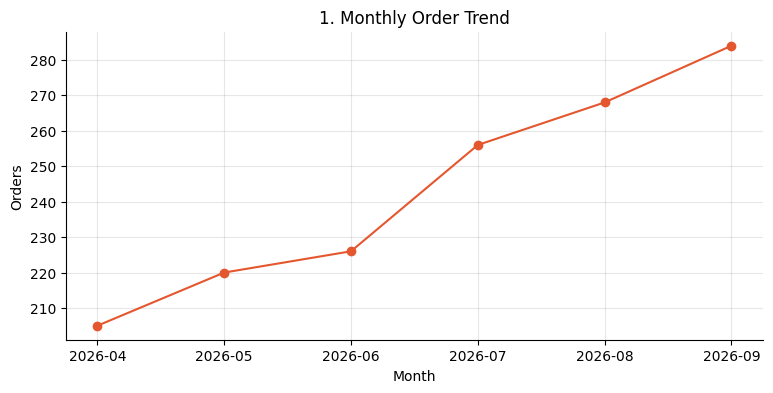

In [39]:
# Chart 1: Monthly order trend (line chart)
plt.plot(monthly["Order_Month"], monthly["Orders"], marker="o", color="#E4572E")
plt.title("1. Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.show()

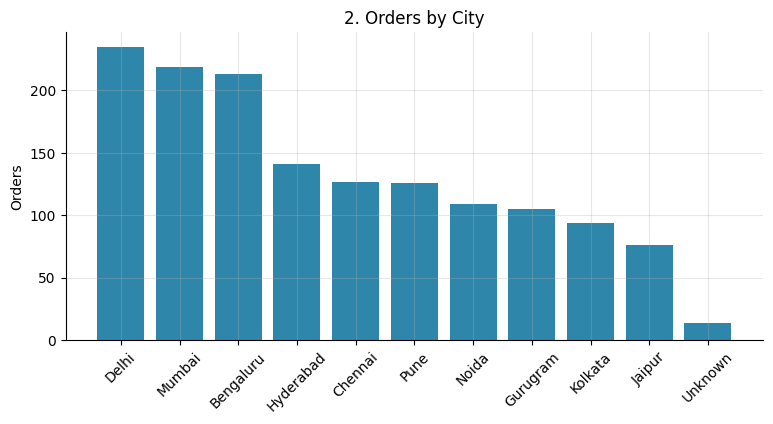

In [40]:
# Chart 2: Orders by city (bar chart)
orders_by_city = df["City"].value_counts()
plt.bar(orders_by_city.index, orders_by_city.values, color="#2E86AB")
plt.title("2. Orders by City")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

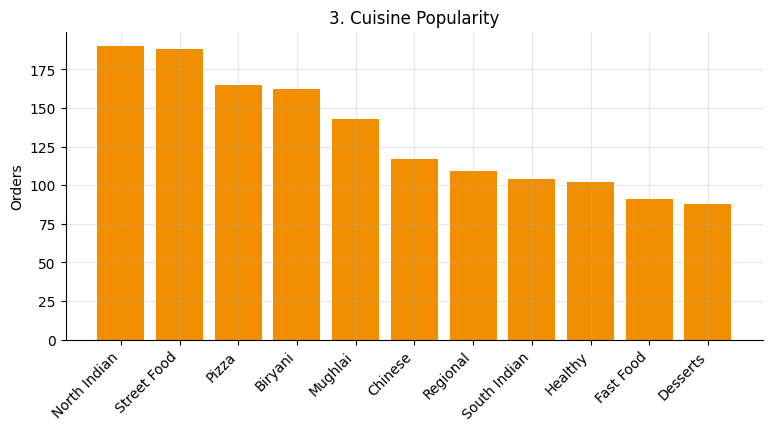

In [41]:
# Chart 3: Cuisine popularity (bar chart)
orders_by_cuisine = df["Cuisine_Type"].value_counts()
plt.bar(orders_by_cuisine.index, orders_by_cuisine.values, color="#F18F01")
plt.title("3. Cuisine Popularity")
plt.ylabel("Orders")
plt.xticks(rotation=45, ha="right")
plt.show()

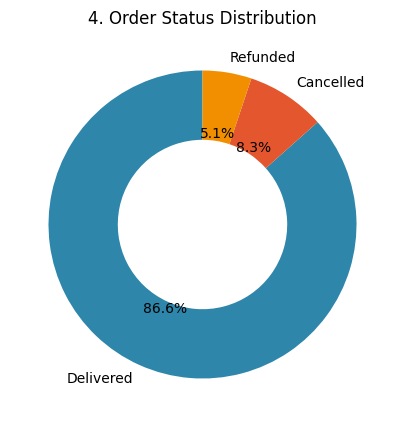

In [42]:
# Chart 4: Order status distribution (donut chart)
status_counts = df["Order_Status"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(status_counts.values, labels=status_counts.index, autopct="%1.1f%%",
        startangle=90, wedgeprops={"width": 0.45}, colors=["#2E86AB", "#E4572E", "#F18F01"])
plt.title("4. Order Status Distribution")
plt.show()

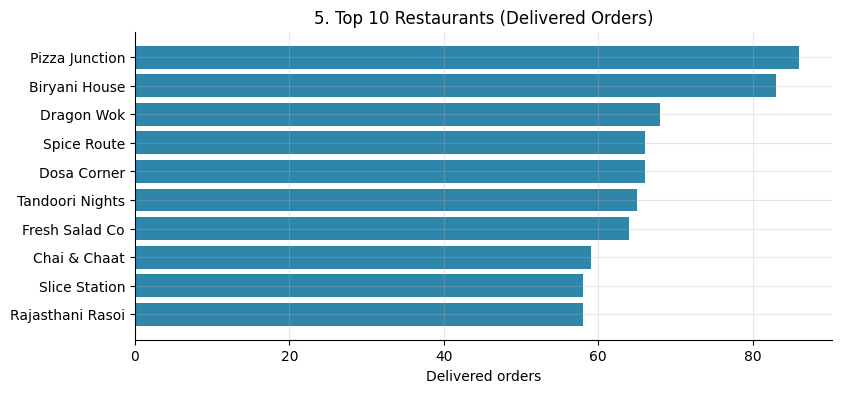

In [43]:
# Chart 5: Restaurant performance (horizontal bar chart) - top 10 by delivered orders
top_10 = restaurant_summary.head(10).sort_values("Delivered_Orders")
plt.barh(top_10["Restaurant_Name"], top_10["Delivered_Orders"], color="#2E86AB")
plt.title("5. Top 10 Restaurants (Delivered Orders)")
plt.xlabel("Delivered orders")
plt.show()

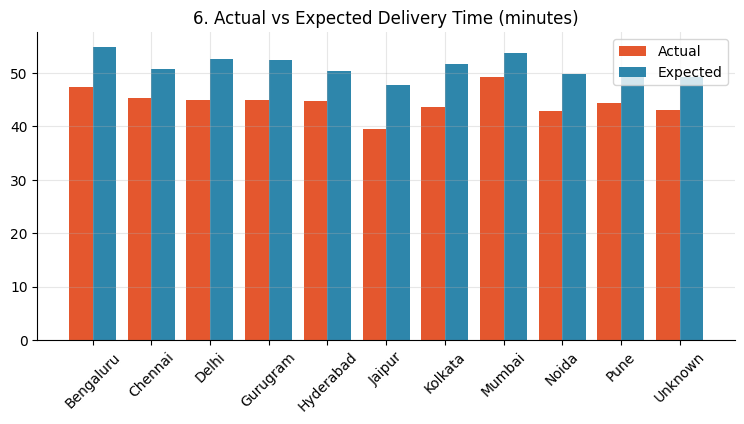

In [44]:
# Chart 6: Actual vs expected delivery time by city (grouped bar chart)
compare = delivered_with_time.groupby("City")[["Delivery_Time_Min", "Expected_Delivery_Time_Min"]].mean()
x_positions = np.arange(len(compare))
plt.bar(x_positions - 0.2, compare["Delivery_Time_Min"], width=0.4, label="Actual", color="#E4572E")
plt.bar(x_positions + 0.2, compare["Expected_Delivery_Time_Min"], width=0.4, label="Expected", color="#2E86AB")
plt.xticks(x_positions, compare.index, rotation=45)
plt.title("6. Actual vs Expected Delivery Time (minutes)")
plt.legend()
plt.show()

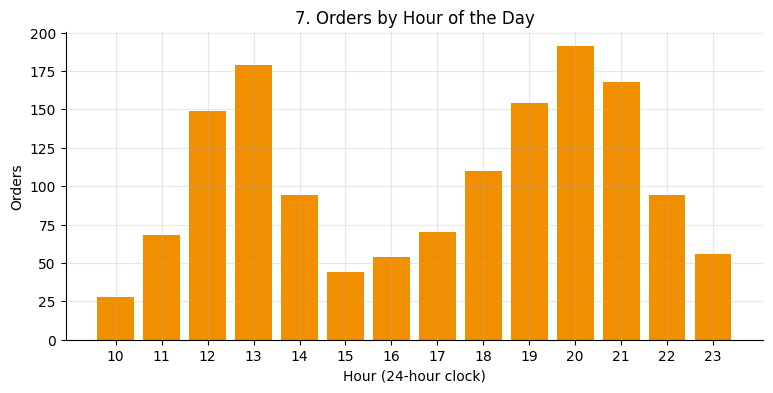

In [45]:
# Chart 7: Orders by hour (bar chart)
plt.bar(orders_by_hour.index, orders_by_hour.values, color="#F18F01")
plt.title("7. Orders by Hour of the Day")
plt.xlabel("Hour (24-hour clock)")
plt.ylabel("Orders")
plt.xticks(range(10, 24))
plt.show()

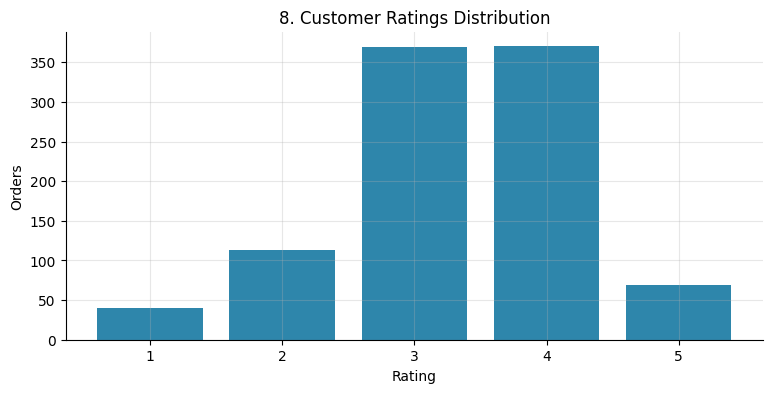

In [46]:
# Chart 8: Customer ratings distribution (bar chart)
rating_counts = df["Customer_Rating"].dropna().astype(int).value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
plt.bar(rating_counts.index, rating_counts.values, color="#2E86AB")
plt.title("8. Customer Ratings Distribution")
plt.xlabel("Rating")
plt.ylabel("Orders")
plt.show()

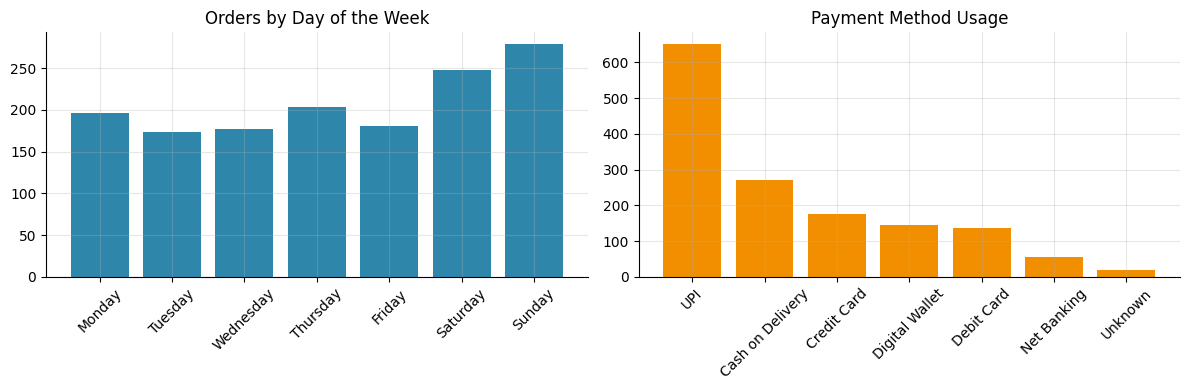

In [47]:
# Extra: Orders by day of the week and payment methods
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(orders_by_day.index, orders_by_day.values, color="#2E86AB")
axes[0].set_title("Orders by Day of the Week")
axes[0].tick_params(axis="x", rotation=45)
payment_counts = df["Payment_Method"].value_counts()
axes[1].bar(payment_counts.index, payment_counts.values, color="#F18F01")
axes[1].set_title("Payment Method Usage")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Step 9: Validation checks
Before trusting the results, we confirm that the files and calculations are consistent.

In [48]:
raw_check = pd.read_csv(RAW_FILE)
clean_check = pd.read_csv(CLEAN_FILE)

assert len(raw_check) == 1500, "Raw file must have exactly 1500 rows"
assert clean_check["Order_ID"].is_unique, "Order_ID must be unique after cleaning"
assert (clean_check["Net_Order_Value"] == clean_check["Order_Value"] - clean_check["Discount"]).all()
assert (clean_check["Total_Order_Amount"] == clean_check["Net_Order_Value"] + clean_check["Delivery_Fee"]).all()
assert clean_check["Order_Status"].isin(["Delivered", "Cancelled", "Refunded"]).all()
assert clean_check["City"].nunique() == 11     # 10 cities + "Unknown"
assert clean_check.loc[clean_check["Order_Status"] != "Delivered", "Is_Late_Delivery"].isna().all()

print("Raw rows     :", len(raw_check))
print("Cleaned rows :", len(clean_check))
print("Rows removed :", len(raw_check) - len(clean_check),
      "(30 duplicates + 3 impossible order values + 8 missing order values)")
print("All validation checks passed.")

Raw rows     : 1500
Cleaned rows : 1459
Rows removed : 41 (30 duplicates + 3 impossible order values + 8 missing order values)
All validation checks passed.


## Step 10: Key findings (calculated from the data)
These sentences are produced by code, so they always match the data.

In [49]:
best_city = df["City"].value_counts().drop("Unknown", errors="ignore").index[0]
best_city_value = delivered.groupby("City")["Order_Value"].sum().drop("Unknown", errors="ignore").idxmax()
best_cuisine = delivered["Cuisine_Type"].value_counts().index[0]
best_restaurant = restaurant_summary.iloc[0]["Restaurant_Name"]
top_payment = df["Payment_Method"].value_counts().index[0]
top_day = orders_by_day.idxmax()
slowest_city = delivered_with_time.groupby("City")["Delivery_Time_Min"].mean().drop("Unknown", errors="ignore").idxmax()

print(f"1. {best_city} has the most orders; {best_city_value} has the highest delivered order value.")
print(f"2. {best_cuisine} is the most popular cuisine; {best_restaurant} completed the most orders.")
print(f"3. Average delivery time is {delivered_with_time['Delivery_Time_Min'].mean():.1f} minutes "
      f"and {delivered_with_time['Is_Late_Delivery'].mean() * 100:.1f}% of deliveries are late.")
print(f"4. {(df['Order_Status'] == 'Cancelled').mean() * 100:.1f}% of orders are cancelled and "
      f"{(df['Order_Status'] == 'Refunded').mean() * 100:.1f}% are refunded.")
print(f"5. {top_payment} is the most used payment method "
      f"({df['Payment_Method'].value_counts(normalize=True).iloc[0] * 100:.1f}% of orders).")
print(f"6. {top_day} is the busiest day and {orders_by_hour.idxmax()}:00 is the busiest hour.")
print(f"7. {slowest_city} has the slowest average delivery time.")
print(f"8. Orders with a discount average Rs {discount_summary.loc['With discount', 'Avg_Order_Value']:.0f} "
      f"versus Rs {discount_summary.loc['No discount', 'Avg_Order_Value']:.0f} without one "
      "(a relationship, not proof that discounts cause bigger orders).")

1. Delhi has the most orders; Delhi has the highest delivered order value.
2. North Indian is the most popular cuisine; Pizza Junction completed the most orders.
3. Average delivery time is 45.4 minutes and 22.7% of deliveries are late.
4. 8.3% of orders are cancelled and 5.1% are refunded.
5. UPI is the most used payment method (44.6% of orders).
6. Sunday is the busiest day and 20:00 is the busiest hour.
7. Mumbai has the slowest average delivery time.
8. Orders with a discount average Rs 449 versus Rs 421 without one (a relationship, not proof that discounts cause bigger orders).


## Limitations
* The data is synthetic, so real business conclusions cannot be drawn from it.
* `Order_Value` is not company revenue (commission, fees and costs are not in the data).
* Only six months of data: no yearly seasonality can be studied.
* Ratings are missing for many delivered orders, so rating averages describe only customers who rated.
* Restaurants appear in all cities (like chains); a real dataset would have restaurant-city pairs.